# Notebook 3 — Resultados

**Práctica 3 · Aprendizaje Automático**

Integrantes: Michael Franco, Michael Lata, Jordy Romero, Nayeli Barbecho

Cuaderno de **resultados**, sobre el export real de ventas de **El Café que te
Conté**: métricas técnicas finales, métricas de negocio, visualizaciones, el
indicador de riesgo por producto y los dos entregables que consume el resto del
proyecto — `metrics/metrics.json` (para la API/CI) y `reports/reporte_ejecutivo.md`
(para una persona no técnica del negocio).

## 1. Carga de modelos y datos de test

In [1]:
import json
import sys
import warnings
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from practica3.features import (  # noqa: E402
    FEATURE_COLS,
    HORIZONTES,
    etiquetas_negocio_top_n,
    split_temporal,
)
from practica3.inference import DemandPredictor  # noqa: E402

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["figure.dpi"] = 110

MODELS_DIR = ROOT / "models"
METRICS_DIR = ROOT / "metrics"
REPORTS_DIR = ROOT / "reports"
METRICS_DIR.mkdir(exist_ok=True)
REPORTS_DIR.mkdir(exist_ok=True)

df = pd.read_parquet(ROOT / "data" / "processed" / "dataset_features.parquet")
features_meta = json.loads((ROOT / "data" / "processed" / "features.json").read_text())
metadata = json.loads((MODELS_DIR / "metadata.json").read_text())
residuales = json.loads((MODELS_DIR / "residuales.json").read_text())
svr_models = {h: joblib.load(MODELS_DIR / f"svr_h{h}.joblib") for h in HORIZONTES}
svc_alerta = joblib.load(MODELS_DIR / "svc_alerta.joblib")
isolation_forest = joblib.load(MODELS_DIR / "isolation_forest.joblib")

# El SVR y el SVC/IsolationForest usan conjuntos de features distintos
# (ver nota de diseño en src/practica3/inference.py).
FEATURE_COLS_SVR = metadata["feature_cols_svr"]
FEATURE_COLS_SVC_ISO = metadata["feature_cols_svc_iso"]

# Reconstruye los mismos splits del notebook 2 (determinista, sin aleatoriedad)
splits = {}
for h in HORIZONTES:
    train, test, corte = split_temporal(df, target_col=f"target_h{h}", feature_cols=FEATURE_COLS_SVR)
    X_test = test[FEATURE_COLS_SVR].values
    y_test = test[f"target_h{h}"].values
    pred_test = svr_models[h].predict(X_test)
    splits[h] = {"train": train, "test": test, "X_test": X_test, "y_test": y_test, "pred_test": pred_test}

# Set de test de SVC/IsolationForest (horizonte 1, mismas filas, más columnas)
X_test_svc_iso = splits[1]["test"][FEATURE_COLS_SVC_ISO].values

print("Modelos y test sets recargados para horizontes:", HORIZONTES)
print(f"Features SVR: {len(FEATURE_COLS_SVR)} de {len(FEATURE_COLS)} candidatas | Features SVC/Iso: {len(FEATURE_COLS_SVC_ISO)}")

Modelos y test sets recargados para horizontes: (1, 3, 7)
Features SVR: 9 de 24 candidatas | Features SVC/Iso: 24


## 2. Métricas técnicas finales

Tabla multi-horizonte, tal como quedó guardada por el notebook 2. El contexto
histórico (Práctica 2 / Informe SVM, dataset sintético) se cita aparte — **no es
comparable numéricamente** (productos, escala y ruido distintos).

In [2]:
tabla_horizontes = pd.DataFrame(metadata["metricas"]).T
tabla_horizontes.index.name = "horizonte"
print("Métricas por horizonte (Práctica 3, datos reales):")
print(tabla_horizontes.round(3).to_string())

ctx = metadata.get("contexto_historico_no_comparable", {})
if ctx.get("practica_2_sintetico"):
    print("\nContexto histórico (dataset sintético — NO comparable numéricamente):")
    print("  Práctica 2   :", ctx["practica_2_sintetico"])
    print("  Informe SVM  :", ctx["informe_svm_sintetico"])

Métricas por horizonte (Práctica 3, datos reales):
             rmse    mae     r2
horizonte                      
1          10.942  7.753  0.464
3          10.984  7.764  0.460
7          10.872  7.458  0.465

Contexto histórico (dataset sintético — NO comparable numéricamente):
  Práctica 2   : {'rmse_test': 7.1248, 'mae_test': 5.2128, 'r2_test': 0.2802}
  Informe SVM  : {'rmse': 5.109958252434942, 'mae': 3.6461547234933778, 'r2': 0.42384687405845634}


## 3. Real vs predicho, por horizonte

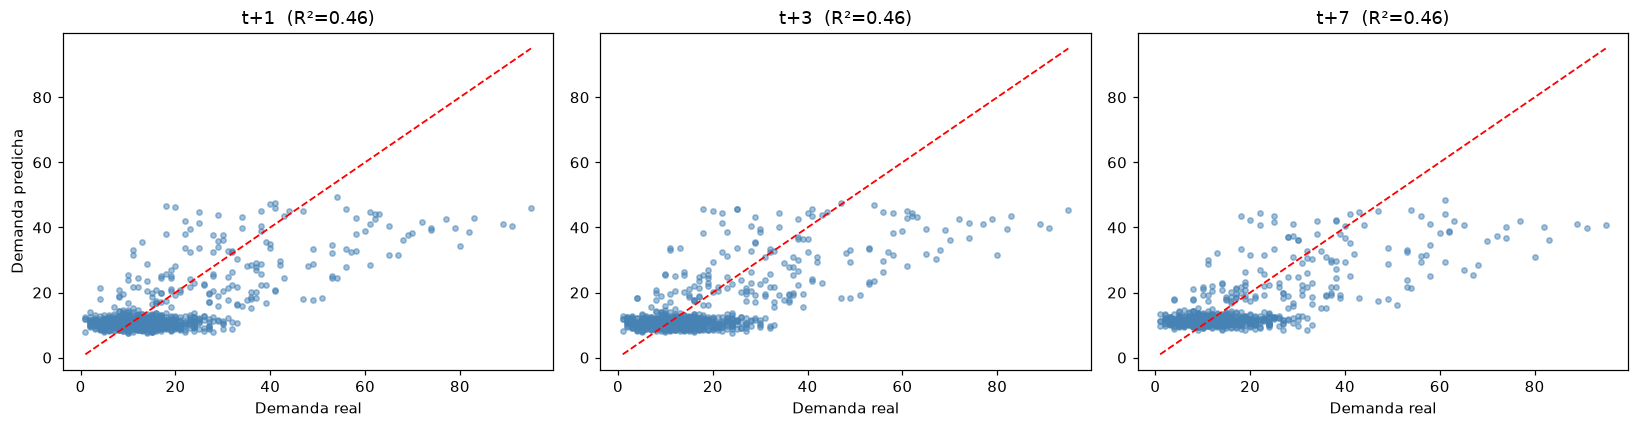

In [3]:
fig, axes = plt.subplots(1, len(HORIZONTES), figsize=(5 * len(HORIZONTES), 4))
for ax, h in zip(axes, HORIZONTES):
    y_true, y_pred = splits[h]["y_test"], splits[h]["pred_test"]
    ax.scatter(y_true, y_pred, s=12, alpha=0.5, color="steelblue")
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    ax.plot(lims, lims, "r--", lw=1.2)
    r2 = metadata["metricas"][str(h)]["r2"]
    ax.set_title(f"t+{h}  (R²={r2:.2f})")
    ax.set_xlabel("Demanda real"); ax.set_ylabel("Demanda predicha" if h == HORIZONTES[0] else "")
plt.tight_layout(); plt.show()

## 4. Serie temporal con escenarios (producto top, horizonte t+1)

Demanda real vs predicha del producto más vendido en el periodo de test, con la
banda **conservador–optimista** calculada en el notebook 2 (§V.D del feedback:
"mostrar intervalos de confianza" y "escenarios optimista/esperado/conservador").

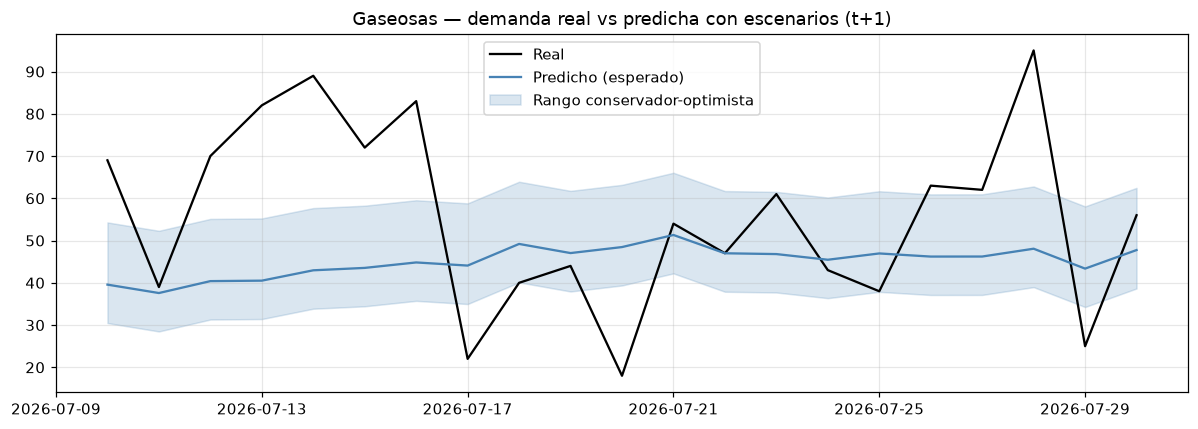

In [4]:
predictor = DemandPredictor()

test_h1 = splits[1]["test"]
pid_top = test_h1.groupby("product_id")["cantidad_vendida"].sum().idxmax()
fechas_top = test_h1[test_h1["product_id"] == pid_top].sort_values("fecha")["fecha"]

registros = [predictor.predecir(int(pid_top), str(f.date()), horizonte=1) for f in fechas_top]
serie = pd.DataFrame(registros)
reales = test_h1[test_h1["product_id"] == pid_top].sort_values("fecha").set_index("fecha")["target_h1"]
serie = serie.set_index(pd.to_datetime(serie["fecha_referencia_datos"]))
nombre_top = test_h1.loc[test_h1["product_id"] == pid_top, "nombre"].iloc[0]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(reales.index, reales.values, label="Real", color="black", lw=1.5)
ax.plot(serie.index, serie["prediccion_esperada"], label="Predicho (esperado)", color="steelblue", lw=1.5)
ax.fill_between(serie.index, serie["escenario_conservador"], serie["escenario_optimista"],
                color="steelblue", alpha=0.2, label="Rango conservador-optimista")
ax.set_title(f"{nombre_top} — demanda real vs predicha con escenarios (t+1)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 5. Métricas de negocio — ingresos en riesgo (precio real)

Punto §V.1 del feedback: métricas orientadas al negocio, no solo técnicas. A
diferencia de la iteración sintética (que usaba costos de ejemplo inventados por
categoría), ahora hay `precio_unitario` **real** por producto — se usa
directamente, sin inventar márgenes: error de predicción × precio real = ingreso en
riesgo. Relevante para El Café que te Conté: varios de sus productos (Pasteles,
Desayunos) son perecederos — el feedback empresarial (`Feedback Empresas.pdf`
§III.A) señaló explícitamente esa preocupación.

In [5]:
precio_por_producto = df.groupby("product_id")["precio_promedio"].mean()

test_h1 = splits[1]["test"].copy()
test_h1["pred"] = splits[1]["pred_test"]
test_h1["pred_naive"] = test_h1["lag_7"]  # baseline: demanda de hace 7 dias
test_h1["precio"] = test_h1["product_id"].map(precio_por_producto)

def ingresos_en_riesgo(df_, col_pred):
    quiebre = (df_["target_h1"] - df_[col_pred]).clip(lower=0) * df_["precio"]  # demanda no atendida
    sobrante = (df_[col_pred] - df_["target_h1"]).clip(lower=0) * df_["precio"]  # preparado de más / posible merma
    return float(quiebre.sum()), float(sobrante.sum())

quiebre_modelo, sobrante_modelo = ingresos_en_riesgo(test_h1, "pred")
quiebre_naive, sobrante_naive = ingresos_en_riesgo(test_h1, "pred_naive")

resumen_negocio = pd.DataFrame([
    {"escenario": "Baseline ingenuo (lag_7)", "ingreso_perdido_quiebre": quiebre_naive,
     "valor_sobrante_posible_merma": sobrante_naive, "total_en_riesgo": quiebre_naive + sobrante_naive},
    {"escenario": "Modelo Práctica 3 (SVR t+1)", "ingreso_perdido_quiebre": quiebre_modelo,
     "valor_sobrante_posible_merma": sobrante_modelo, "total_en_riesgo": quiebre_modelo + sobrante_modelo},
]).round(2)
reduccion_pct = 100 * (1 - resumen_negocio.loc[1, "total_en_riesgo"] / resumen_negocio.loc[0, "total_en_riesgo"])
print(resumen_negocio.to_string(index=False))
print(f"\nReducción de ingresos en riesgo usando el modelo vs baseline ingenuo: {reduccion_pct:.1f}%")
print("(basado en precio_unitario real del periodo de test, sin márgenes inventados)")

                  escenario  ingreso_perdido_quiebre  valor_sobrante_posible_merma  total_en_riesgo
   Baseline ingenuo (lag_7)                 18091.72                      14720.07         32811.79
Modelo Práctica 3 (SVR t+1)                 16027.67                       6136.33         22163.99

Reducción de ingresos en riesgo usando el modelo vs baseline ingenuo: 32.5%
(basado en precio_unitario real del periodo de test, sin márgenes inventados)


## 6. Detección de anomalías — resumen en test

In [6]:
pred_anom = isolation_forest.predict(X_test_svc_iso)
test_h1["anomalia"] = pred_anom == -1
n_anom = int(test_h1["anomalia"].sum())
print(f"Compras/ventas marcadas como atípicas en test: {n_anom} / {len(test_h1)} ({n_anom/len(test_h1):.1%})")
cols = ["fecha", "product_id", "nombre", "cantidad_vendida", "target_h1", "pred"]
test_h1[test_h1["anomalia"]][cols].sort_values("fecha").head(10)

Compras/ventas marcadas como atípicas en test: 72 / 688 (10.5%)


,fecha,product_id,nombre,cantidad_vendida,target_h1,pred
8,2026-07-10,15,Gaseosas,34,69.0,37.608836
23,2026-07-10,7,Café,22,79.0,39.776209
45,2026-07-11,28,Smoothies,42,36.0,28.550402
46,2026-07-11,15,Gaseosas,69,39.0,35.619069
47,2026-07-11,7,Café,79,30.0,36.103681
61,2026-07-11,18,Jugos,48,20.0,28.267234
94,2026-07-12,15,Gaseosas,39,70.0,38.438006
96,2026-07-12,7,Café,30,74.0,39.701034
115,2026-07-13,28,Smoothies,61,42.0,29.764187
117,2026-07-13,7,Café,74,74.0,39.066270


## 7. Importancia de variables — resumen final

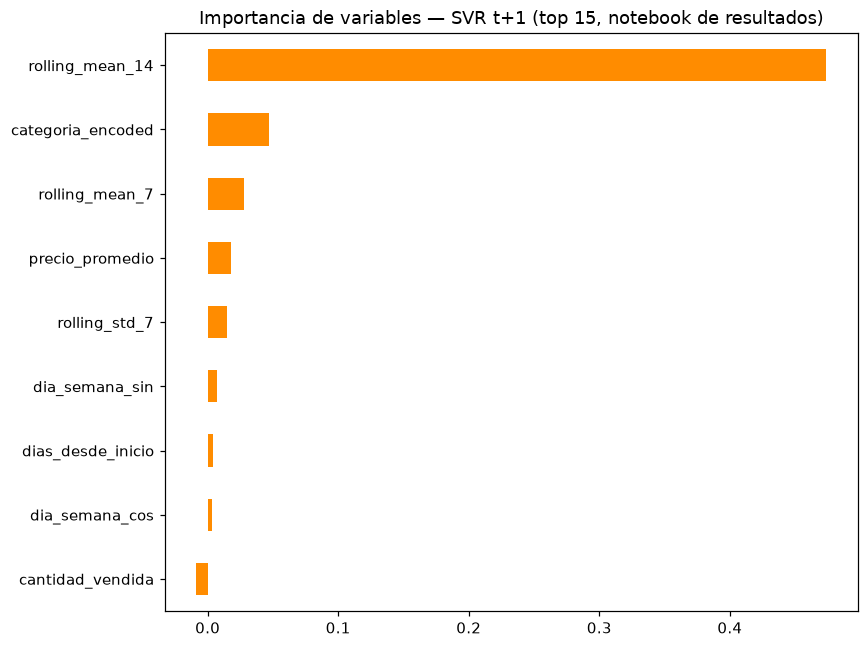

Top 5 variables más influyentes:
  rolling_mean_14           0.4740
  categoria_encoded         0.0467
  rolling_mean_7            0.0279
  precio_promedio           0.0175
  rolling_std_7             0.0151


In [7]:
perm = permutation_importance(
    svr_models[1], splits[1]["X_test"], splits[1]["y_test"], n_repeats=20, random_state=42, n_jobs=-1
)
importancia = pd.Series(perm.importances_mean, index=FEATURE_COLS_SVR).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
importancia.head(15).iloc[::-1].plot.barh(ax=ax, color="darkorange")
ax.set_title("Importancia de variables — SVR t+1 (top 15, notebook de resultados)")
plt.tight_layout(); plt.show()

top5 = importancia.head(5)
print("Top 5 variables más influyentes:")
for nombre, val in top5.items():
    print(f"  {nombre:25s} {val:.4f}")

## 8. Indicador de riesgo — semáforo por producto

Punto §V.7 del feedback: un indicador fácil de interpretar. Para cada producto se
calcula la predicción de mañana (t+1) a partir de su última fecha disponible, con su
nivel de riesgo (verde/amarillo/rojo) según ancho del intervalo y calidad de datos.

In [8]:
EMOJI_RIESGO = {"verde": "🟢", "amarillo": "🟡", "rojo": "🔴"}
fecha_max = df["fecha"].max()
semaforo = []
for pid in sorted(df["product_id"].unique()):
    r = predictor.predecir(int(pid), str(fecha_max.date()), horizonte=1)
    nombre = df.loc[df["product_id"] == pid, "nombre"].iloc[0]
    semaforo.append({
        "product_id": pid, "nombre": nombre,
        "prediccion_manana": r["prediccion_esperada"],
        "rango": f"{r['escenario_conservador']}–{r['escenario_optimista']}",
        "nivel_riesgo": r["nivel_riesgo"],
        "datos_historicos_suficientes": r["datos_historicos_suficientes"],
        "alerta_anomalia": r["alerta_anomalia"],
        "riesgo": EMOJI_RIESGO[r["nivel_riesgo"]] + " " + r["nivel_riesgo"],
        "alerta_alta_demanda": r["alerta_alta_demanda"],
    })
semaforo_df = pd.DataFrame(semaforo)
print(semaforo_df.drop(columns=["nivel_riesgo"]).to_string(index=False))

 product_id                            nombre  prediccion_manana       rango  datos_historicos_suficientes  alerta_anomalia     riesgo  alerta_alta_demanda
          1                       Affo Cookie               9.63  0.54–24.35                          True            False 🟡 amarillo                False
          2                              Agua              26.49  17.4–41.21                          True            False 🟡 amarillo                False
          3                     Avocado Toast              11.14  2.05–25.86                          True            False 🟡 amarillo                False
          4              Bacon Egg and Cheese              10.09   1.0–24.82                          True            False 🟡 amarillo                False
          5                   Bananella Toast              10.41  1.32–25.13                          True            False 🟡 amarillo                False
          6                   Break Your Diet              12.44

## 9. `metrics/metrics.json` — métricas ordenadas

In [9]:
metrics_json = {
    "proyecto": "Practica_3 - Prediccion de demanda (SVR multi-horizonte)",
    "generado_en": datetime.now().isoformat(timespec="seconds"),
    "dataset": {
        "origen": "real (ventas.csv, El Café que te Conté, 2026-04-01 a 2026-07-31)",
        "n_productos": int(df["product_id"].nunique()),
        "n_dias": int(df["fecha"].nunique()),
        "n_features_candidatas": len(FEATURE_COLS),
        "n_features_svr": len(FEATURE_COLS_SVR),
        "n_features_svc_iso": len(FEATURE_COLS_SVC_ISO),
    },
    "metricas_tecnicas_por_horizonte": metadata["metricas"],
    "contexto_historico_no_comparable": metadata.get("contexto_historico_no_comparable"),
    "clasificador_alerta_alta_demanda": metadata["svc_alerta"],
    "deteccion_anomalias": {
        "contamination": metadata["isolation_forest"]["contamination"],
        "n_anomalias_test": n_anom,
        "pct_anomalias_test": round(n_anom / len(test_h1), 4),
    },
    "metricas_negocio_t1": {
        "ingresos_en_riesgo_baseline_ingenuo": resumen_negocio.loc[0, "total_en_riesgo"],
        "ingresos_en_riesgo_modelo": resumen_negocio.loc[1, "total_en_riesgo"],
        "reduccion_pct": round(reduccion_pct, 2),
        "nota": "precio_unitario real, sin margenes inventados — ver docs/02_glosario.md",
    },
    "importancia_variables_top5": top5.round(4).to_dict(),
    "features_descartadas_svr": metadata["features_descartadas_svr"],
    "semaforo_riesgo_actual": semaforo_df.drop(columns=["riesgo"]).to_dict("records"),
}

with open(METRICS_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics_json, f, indent=2, ensure_ascii=False)

print("Guardado: metrics/metrics.json")
print(json.dumps(metrics_json["metricas_tecnicas_por_horizonte"], indent=2))

Guardado: metrics/metrics.json
{
  "1": {
    "rmse": 10.9421,
    "mae": 7.7534,
    "r2": 0.4644
  },
  "3": {
    "rmse": 10.9844,
    "mae": 7.7643,
    "r2": 0.4602
  },
  "7": {
    "rmse": 10.8716,
    "mae": 7.4578,
    "r2": 0.4646
  }
}


## 10. Reporte ejecutivo (no técnico)

Punto §V.6 del feedback: reportes automáticos dirigidos a usuarios empresariales,
en lenguaje simple — pensado para el equipo de El Café que te Conté, sin necesidad
de entender SVR, R² ni intervalos de confianza.

In [10]:
lineas = []
lineas.append("# Reporte ejecutivo de demanda — El Café que te Conté\n\n")
lineas.append(f"_Generado automáticamente el {datetime.now():%Y-%m-%d %H:%M}_\n\n")
lineas.append(
    "Este reporte resume, en lenguaje simple, qué tan bien predice el sistema la "
    "demanda de cada producto y qué se espera para mañana. Está calculado sobre las "
    "ventas reales de la cafetería (abril-julio 2026).\n\n"
)
lineas.append("## ¿Qué tan confiable es el sistema?\n\n")
r2_t1 = metadata['metricas']['1']['r2']
lineas.append(
    f"- En promedio, el modelo explica **{r2_t1:.0%}** de las variaciones de la demanda del día "
    "siguiente.\n"
    f"- Usar el modelo, en vez de simplemente repetir la venta de la semana pasada, "
    f"reduciría los ingresos en riesgo (por quiebre de stock o producto preparado de más) "
    f"en un **{reduccion_pct:.0f}%**, calculado con los precios reales del menú.\n\n"
)
lineas.append("## Predicción para mañana, por producto\n\n")
lineas.append("| Producto | Predicción | Rango esperado | Riesgo | Alerta alta demanda |\n")
lineas.append("|---|---|---|---|---|\n")
for row in semaforo:
    lineas.append(
        f"| {row['nombre']} | {row['prediccion_manana']:.0f} u. | {row['rango']} u. | "
        f"{row['riesgo']} | {'Sí' if row['alerta_alta_demanda'] else 'No'} |\n"
    )
lineas.append("\n## ¿Qué mueve más la predicción?\n\n")
for etiqueta in etiquetas_negocio_top_n(importancia, n=5):
    lineas.append(f"- {etiqueta}\n")

rojos = [r for r in semaforo if r["nivel_riesgo"] == "rojo"]
rojos_por_datos = [r["nombre"] for r in rojos if not r["datos_historicos_suficientes"]]
rojos_por_anomalia = [r["nombre"] for r in rojos if r["datos_historicos_suficientes"] and r["alerta_anomalia"]]

lineas.append(
    "\n## Limitaciones actuales\n\n"
    "- El modelo se entrenó con 4 meses de historia (abril-julio 2026) — mientras más "
    "meses de ventas se acumulen, mejores serán las predicciones.\n"
    "- No se cuenta todavía con datos de promociones ni clima; si la cafetería empieza "
    "a registrar promociones activas, se pueden incorporar para mejorar la precisión.\n"
    f"- Un producto sale en 🔴 por dos motivos posibles: historial insuficiente (mínimo "
    f"{features_meta['min_dias_historicos']} días) o porque su situación actual (ventas "
    "recientes, contexto) es distinta a lo habitual y el sistema prefiere avisar en vez "
    "de predecir con falsa confianza.\n"
)
if rojos_por_anomalia:
    lineas.append(
        f"- Hoy están en 🔴 por contexto atípico (no por falta de historial): "
        f"{', '.join(rojos_por_anomalia)}. Vale la pena revisar sus ventas de los "
        "últimos días antes de confiar en la predicción.\n"
    )
if rojos_por_datos:
    lineas.append(f"- Hoy están en 🔴 por historial insuficiente: {', '.join(rojos_por_datos)}.\n")

reporte_md = "".join(lineas)
(REPORTS_DIR / "reporte_ejecutivo.md").write_text(reporte_md, encoding="utf-8")
print(f"Guardado: reports/reporte_ejecutivo.md ({len(reporte_md.splitlines())} líneas)")
print(reporte_md)

Guardado: reports/reporte_ejecutivo.md (63 líneas)
# Reporte ejecutivo de demanda — El Café que te Conté

_Generado automáticamente el 2026-07-08 17:39_

Este reporte resume, en lenguaje simple, qué tan bien predice el sistema la demanda de cada producto y qué se espera para mañana. Está calculado sobre las ventas reales de la cafetería (abril-julio 2026).

## ¿Qué tan confiable es el sistema?

- En promedio, el modelo explica **46%** de las variaciones de la demanda del día siguiente.
- Usar el modelo, en vez de simplemente repetir la venta de la semana pasada, reduciría los ingresos en riesgo (por quiebre de stock o producto preparado de más) en un **32%**, calculado con los precios reales del menú.

## Predicción para mañana, por producto

| Producto | Predicción | Rango esperado | Riesgo | Alerta alta demanda |
|---|---|---|---|---|
| Affo Cookie | 10 u. | 0.54–24.35 u. | 🟡 amarillo | No |
| Agua | 26 u. | 17.4–41.21 u. | 🟡 amarillo | No |
| Avocado Toast | 11 u. | 2.05–25.86 u. | 

## Conclusiones

- Primera corrida completa del pipeline sobre **datos reales** de El Café que te
  Conté, documentada en `metrics/metrics.json` (no comparable numéricamente con los
  resultados de la etapa sintética — dataset distinto).
- Se entregan los 7 puntos de mejora de `Feedback Empresas.pdf` §V: horizontes
  múltiples, intervalos/escenarios, importancia de variables, anomalías, métricas de
  negocio con **precio real** (no inventado), reporte automático no técnico e
  indicador de riesgo fácil de leer.
- Se corrigió un error metodológico real detectado en este mismo run: el SVC de
  alerta y el IsolationForest no deben reusar las features podadas para el SVR
  (bajaba su AUC a 0.47, peor que azar) — usan las 24 candidatas completas.
- `reports/reporte_ejecutivo.md` y `metrics/metrics.json` son los artefactos que
  consumirían un usuario de negocio y la API/CI respectivamente — ambos se generan
  automáticamente al correr `make pipeline`.